# Experimento grande: representación a escala grande — CCSN

**Objetivo:** entrenar `CloudCNNGrande` usando las imágenes originales `data/processed`, sin recorte, con BatchNorm, LeakyReLU y dropout 0.3. Se mantienen 15 épocas, batch 64 y la misma semilla para comparar los tres experimentos.

**Sin modificar otros `.py`:** se reutilizan `clouds_cnn.engine.fit`, `make_split_loader`, métricas y gráficos existentes, pero **no** `run_experiment`, pues este último construye la CNN original. No se evalúa `test` para seleccionar el modelo. El checkpoint y las métricas se guardan con el nombre propio de esta arquitectura.

## 1. Importaciones y rutas

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torchvision.datasets import ImageFolder

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src" / "clouds_cnn").is_dir(), "Abre el notebook desde la raíz o notebooks/"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from clouds_cnn.config import ExperimentConfig
from clouds_cnn.data import load_dataset_stats, make_split_loader
from clouds_cnn.engine import fit
from clouds_cnn.inspection import capture_feature_maps
from clouds_cnn.metrics import collect_predictions, classification_report
from clouds_cnn.models_grande import CloudCNNGrande
from clouds_cnn.plots import plot_feature_maps, plot_training_curves, denormalize
from clouds_cnn.utils import get_device, set_seed

print("Raíz:", ROOT)
print("PyTorch:", torch.__version__)

Raíz: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal
PyTorch: 2.14.1+cpu


## 2. Configuración y verificación de datos

In [8]:
config = ExperimentConfig(
    run_name="escala_grande_06",
    batch_size=64,
    num_workers=0,
    use_batchnorm=True,
    dropout_p=0.3,
    epochs=15,
    device_preference="auto",
    data_root=ROOT / "data" / "processed",
    output_root=ROOT / "outputs",
)
assert config.num_classes == 11 and config.image_size == 256
assert config.center_crop is None
assert (config.data_root / "dataset_stats.json").is_file()

SALIDA = config.output_root / "metricas" / config.run_name
SALIDA.mkdir(parents=True, exist_ok=True)
CHECKPOINT = config.output_root / "checkpoints" / f"{config.run_name}_best.pt"
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

stats = load_dataset_stats(config.data_root)
print(config)
print("Salida:", SALIDA)

ExperimentConfig(run_name='escala_grande_06', split_seed=2026, train_seed=2026, deterministic=False, num_classes=11, image_size=256, center_crop=None, batch_size=64, num_workers=0, use_batchnorm=True, dropout_p=0.3, learning_rate=0.001, weight_decay=0.0, epochs=15, device_preference='auto', data_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/data/processed'), output_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/outputs'), mlflow_experiment_name='clouds-cnn-from-scratch')
Salida: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\escala_grande_06


## 3. Distribución de imágenes: train, val y test (solo conteos)

Particiones:


,imagenes,porcentaje
train,1766,70.00%
val,378,14.98%
test,379,15.02%


Imágenes por clase:


,train,val,test
clase,,,
Ac,153,33,33
As,130,28,27
Cb,165,35,36
Cc,186,39,40
Ci,97,21,21
Cs,200,43,43
Ct,140,30,30
Cu,124,27,26
Ns,192,41,41


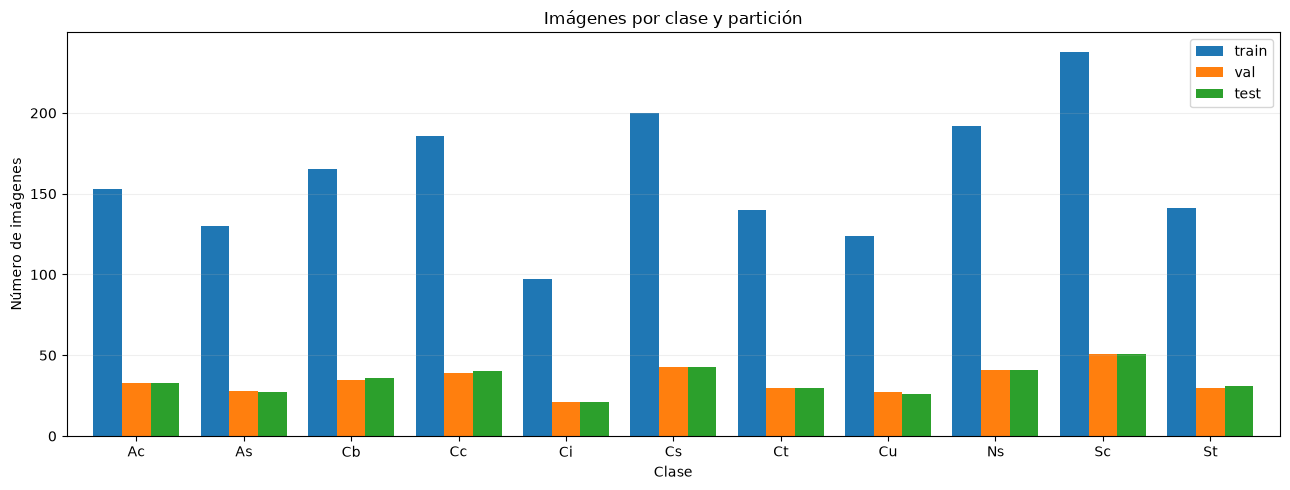

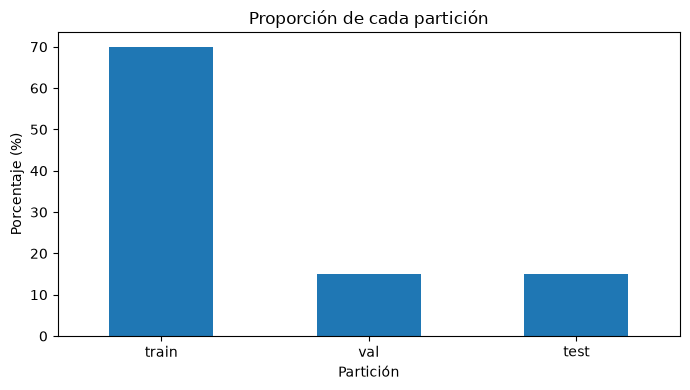

In [9]:
splits = ("train", "val", "test")
conteos = {}
for split in splits:
    dataset = ImageFolder(config.data_root / split)
    conteos[split] = pd.Series(
        np.bincount(dataset.targets, minlength=len(dataset.classes)),
        index=dataset.classes,
        dtype=int,
    )

clases = list(conteos["train"].index)
assert len(clases) == config.num_classes
assert all(list(conteos[s].index) == clases for s in splits)

distribucion = pd.DataFrame(conteos)
distribucion.index.name = "clase"
resumen_splits = distribucion.sum().rename("imagenes").to_frame()
resumen_splits["porcentaje"] = resumen_splits["imagenes"] / resumen_splits["imagenes"].sum()

print("Particiones:")
display(resumen_splits.style.format({"porcentaje": "{:.2%}"}))
print("Imágenes por clase:")
display(distribucion.style.background_gradient(cmap="Blues"))

distribucion.to_csv(SALIDA / "distribucion_por_clase.csv")
resumen_splits.to_csv(SALIDA / "distribucion_particiones.csv")

ax = distribucion.plot.bar(figsize=(13, 5), width=0.8)
ax.set(title="Imágenes por clase y partición", ylabel="Número de imágenes", xlabel="Clase")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
fig = ax.figure
fig.tight_layout()
fig.savefig(SALIDA / "distribucion_por_clase.png", dpi=180)
plt.show()
plt.close(fig)

ax = resumen_splits["porcentaje"].mul(100).plot.bar(figsize=(7, 4))
ax.set(title="Proporción de cada partición", ylabel="Porcentaje (%)", xlabel="Partición")
ax.tick_params(axis="x", rotation=0)
fig = ax.figure
fig.tight_layout()
fig.savefig(SALIDA / "proporcion_particiones.png", dpi=180)
plt.show()
plt.close(fig)

## 4. Construir el modelo y comprobar sus dimensiones

In [10]:
set_seed(config.train_seed, deterministic=config.deterministic)
device = get_device(config.device_preference)
modelo = CloudCNNGrande(
    num_classes=config.num_classes,
    use_batchnorm=config.use_batchnorm,
    dropout_p=config.dropout_p,
).to(device)

with torch.inference_mode():
    modelo.eval()
    logits = modelo(torch.zeros(1, 3, 256, 256, device=device))
assert logits.shape == (1, 11)

parametros = sum(p.numel() for p in modelo.parameters())
print("Dispositivo:", device)
print("Modelo:", type(modelo).__name__)
print("Parámetros:", f"{parametros:,}")
print(modelo)

Dispositivo: cpu
Modelo: CloudCNNGrande
Parámetros: 558,123
CloudCNNGrande(
  (features): Sequential(
    (block1): Sequential(
      (conv): Conv2d(3, 32, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
      (norm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): LeakyReLU(negative_slope=0.1)
      (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
    )
    (block2): Sequential(
      (conv): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
      (norm): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): LeakyReLU(negative_slope=0.1)
      (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
    )
    (block3): Sequential(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (norm): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act

## 5. Entrenamiento (una sola ejecución)

Se usa el motor original `fit` directamente, para pasarle **este** modelo sin cambiar `experiment.py`. Selecciona el mejor checkpoint por menor `val_loss`. Si el archivo ya existe, la celda exige autorización explícita para sobrescribirlo.

In [11]:
REENTRENAR = False
if CHECKPOINT.exists() and not REENTRENAR:
    raise FileExistsError(
        f"Ya existe {CHECKPOINT}. Cambia REENTRENAR=True si deseas sobrescribirlo. "
        "Si solo quieres consultar resultados, ejecuta la celda de recuperación."
    )

set_seed(config.train_seed, deterministic=config.deterministic)
modelo = type(modelo)(
    num_classes=config.num_classes,
    use_batchnorm=config.use_batchnorm,
    dropout_p=config.dropout_p,
).to(device)
train_loader = make_split_loader(config, "train", device)
val_loader = make_split_loader(config, "val", device)
assert train_loader.dataset.classes == val_loader.dataset.classes

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    modelo.parameters(),
    lr=config.learning_rate,
    weight_decay=config.weight_decay,
)
historial = fit(
    model=modelo,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
    config=config,
    checkpoint_path=CHECKPOINT,
    verbose=True,
)
print("Mejor época:", historial["best_epoch"])
print("Checkpoint:", CHECKPOINT)

Época   1/15 | train loss 2.1997 acc 0.2118 | val loss 2.1574 acc 0.2169 | 175.9s *
Época   2/15 | train loss 2.0475 acc 0.2707 | val loss 1.9827 acc 0.2751 | 441.0s *
Época   3/15 | train loss 2.0230 acc 0.2956 | val loss 2.0241 acc 0.2566 | 2879.4s
Época   4/15 | train loss 1.9831 acc 0.3097 | val loss 2.0114 acc 0.2937 | 193.9s
Época   5/15 | train loss 1.9471 acc 0.3109 | val loss 2.0325 acc 0.2487 | 186.8s
Época   6/15 | train loss 1.9307 acc 0.3177 | val loss 2.0568 acc 0.2434 | 194.9s
Época   7/15 | train loss 1.8977 acc 0.3443 | val loss 2.0059 acc 0.2778 | 208.3s
Época   8/15 | train loss 1.8677 acc 0.3403 | val loss 1.9621 acc 0.3280 | 206.4s *
Época   9/15 | train loss 1.8688 acc 0.3420 | val loss 1.9410 acc 0.2989 | 204.2s *
Época  10/15 | train loss 1.8278 acc 0.3641 | val loss 1.9579 acc 0.2672 | 203.1s
Época  11/15 | train loss 1.7969 acc 0.3681 | val loss 1.9200 acc 0.3069 | 203.7s *
Época  12/15 | train loss 1.7797 acc 0.3669 | val loss 1.8844 acc 0.2963 | 204.4s *
Épo

## 6. Recuperar el checkpoint y el historial sin volver a entrenar

La celda también funciona después de reiniciar el kernel, siempre que se haya ejecutado el entrenamiento y exista el checkpoint. El historial completo se guarda en la celda siguiente.

In [12]:
assert CHECKPOINT.is_file(), "Primero entrena el modelo en la sección 5"
modelo = CloudCNNGrande(
    num_classes=config.num_classes,
    use_batchnorm=config.use_batchnorm,
    dropout_p=config.dropout_p,
).to(device)
checkpoint = torch.load(CHECKPOINT, map_location=device, weights_only=True)
assert checkpoint["config"]["run_name"] == config.run_name
modelo.load_state_dict(checkpoint["model_state_dict"])
modelo.eval()

if "historial" not in globals():
    archivo_historial = SALIDA / "historial.json"
    if archivo_historial.is_file():
        historial = json.loads(archivo_historial.read_text(encoding="utf-8"))
    else:
        historial = None
print("Checkpoint cargado; mejor época:", checkpoint["epoch"])
print("Pérdida de validación:", checkpoint["val_loss"])

Checkpoint cargado; mejor época: 12
Pérdida de validación: 1.8843677662037037


## 7. Curvas y métricas por época

,epoca,train_loss,val_loss,train_acc,val_acc,lr,epoch_time
0,1,2.199682,2.157352,21.18%,21.69%,0.001000,175.916320
1,2,2.047539,1.982738,27.07%,27.51%,0.001000,440.975744
2,3,2.023037,2.024067,29.56%,25.66%,0.001000,2879.408259
3,4,1.983104,2.011436,30.97%,29.37%,0.001000,193.913761
4,5,1.947145,2.032548,31.09%,24.87%,0.001000,186.766869
5,6,1.930706,2.056806,31.77%,24.34%,0.001000,194.897293
6,7,1.897687,2.005855,34.43%,27.78%,0.001000,208.321592
7,8,1.867664,1.962123,34.03%,32.80%,0.001000,206.433375
8,9,1.868824,1.940988,34.20%,29.89%,0.001000,204.193323
9,10,1.827787,1.957903,36.41%,26.72%,0.001000,203.114837


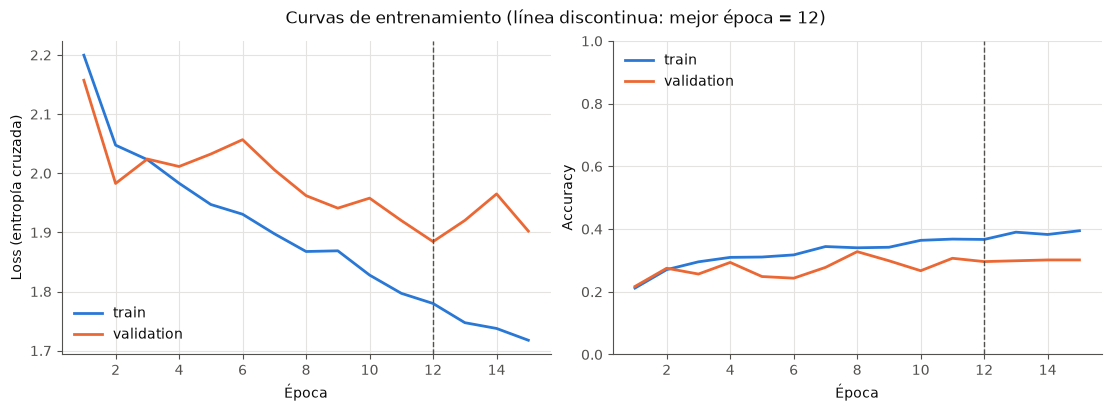

In [13]:
if historial is not None:
    (SALIDA / "historial.json").write_text(
        json.dumps(historial, indent=2), encoding="utf-8"
    )
    tabla_epocas = pd.DataFrame({
        "epoca": range(1, len(historial["train_loss"]) + 1),
        "train_loss": historial["train_loss"],
        "val_loss": historial["val_loss"],
        "train_acc": historial["train_acc"],
        "val_acc": historial["val_acc"],
        "lr": historial["lr"],
        "epoch_time": historial["epoch_time"],
    })
    tabla_epocas.to_csv(SALIDA / "historial_epocas.csv", index=False)
    display(tabla_epocas.style.format({"train_acc": "{:.2%}", "val_acc": "{:.2%}"}))
    fig = plot_training_curves(historial)
    fig.savefig(SALIDA / "curvas_entrenamiento.png", dpi=180, bbox_inches="tight")
    display(fig)
    plt.close(fig)
else:
    print("No se guardó historial: disponible solo el mejor checkpoint.")

## 8. Evaluación final del mejor checkpoint en train y val

Las métricas se calculan sobre el **mismo conjunto de pesos** en modo evaluación. No se usa test.

In [14]:
# Los loaders de evaluación no barajan los datos.
from torch.utils.data import DataLoader

resultados = {}
for split in ("train", "val"):
    base_loader = make_split_loader(config, split, device)
    loader = DataLoader(
        base_loader.dataset,
        batch_size=config.batch_size,
        shuffle=False,
        num_workers=config.num_workers,
    )
    pred = collect_predictions(modelo, loader, nn.CrossEntropyLoss(), device)
    rep = classification_report(pred.y_true, pred.y_pred, config.num_classes)
    resultados[split] = {"pred": pred, "rep": rep}
    print(f"{split}: n={len(pred.y_true)} | loss={pred.loss:.4f} | "
          f"accuracy={rep.accuracy:.2%} | macro-F1={rep.macro_f1:.4f}")

train: n=1766 | loss=1.6936 | accuracy=40.77% | macro-F1=0.3529
val: n=378 | loss=1.8844 | accuracy=29.63% | macro-F1=0.2384


## 9. Métricas por clase, soporte e intervalos de Wilson

In [15]:
def wilson(aciertos, total, z=1.96):
    """Intervalo de Wilson aproximado al 95 %."""
    if total == 0:
        return np.nan, np.nan
    p = aciertos / total
    den = 1 + z**2 / total
    centro = (p + z**2 / (2 * total)) / den
    margen = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / den
    return centro - margen, centro + margen

resumen = []
for split, resultado in resultados.items():
    rep = resultado["rep"]
    cm = rep.confusion_matrix.numpy()
    soporte = cm.sum(axis=1)
    filas = []
    for i, clase in enumerate(clases):
        li, ls = wilson(int(cm[i, i]), int(soporte[i]))
        filas.append({
            "clase": clase, "soporte": int(soporte[i]),
            "aciertos": int(cm[i, i]),
            "precision": float(rep.precision[i]),
            "recall": float(rep.recall[i]),
            "f1": float(rep.f1[i]),
            "ic95_inferior": li, "ic95_superior": ls,
        })
    tabla = pd.DataFrame(filas)
    tabla.to_csv(SALIDA / f"metricas_por_clase_{split}.csv", index=False)
    print("Métricas por clase:", split)
    display(tabla.style.format({
        "precision": "{:.2%}", "recall": "{:.2%}", "f1": "{:.2%}",
        "ic95_inferior": "{:.2%}", "ic95_superior": "{:.2%}",
    }).background_gradient(cmap="RdYlGn", subset=["precision", "recall", "f1"], vmin=0, vmax=1))
    total = int(soporte.sum())
    ci = wilson(int(np.trace(cm)), total)
    resumen.append({
        "particion": split, "imagenes": total,
        "loss": resultado["pred"].loss,
        "accuracy": rep.accuracy,
        "macro_f1": rep.macro_f1,
        "f1_ponderado": float(np.average(rep.f1.numpy(), weights=soporte)),
        "ic95_inferior": ci[0], "ic95_superior": ci[1],
    })

resumen = pd.DataFrame(resumen)
resumen.to_csv(SALIDA / "metricas_generales.csv", index=False)
display(resumen.style.format({
    "accuracy": "{:.2%}", "macro_f1": "{:.2%}",
    "f1_ponderado": "{:.2%}", "ic95_inferior": "{:.2%}",
    "ic95_superior": "{:.2%}", "loss": "{:.4f}",
}))

Métricas por clase: train


,clase,soporte,aciertos,precision,recall,f1,ic95_inferior,ic95_superior
0,Ac,153,24,31.17%,15.69%,20.87%,10.77%,22.28%
1,As,130,43,46.24%,33.08%,38.57%,25.58%,41.55%
2,Cb,165,118,39.86%,71.52%,51.19%,64.20%,77.85%
3,Cc,186,104,36.49%,55.91%,44.16%,48.73%,62.86%
4,Ci,97,19,28.79%,19.59%,23.31%,12.91%,28.58%
5,Cs,200,27,42.86%,13.50%,20.53%,9.45%,18.93%
6,Ct,140,90,56.96%,64.29%,60.40%,56.06%,71.74%
7,Cu,124,32,52.46%,25.81%,34.59%,18.91%,34.15%
8,Ns,192,100,35.84%,52.08%,42.46%,45.05%,59.04%
9,Sc,238,163,42.01%,68.49%,52.08%,62.33%,74.06%


Métricas por clase: val


,clase,soporte,aciertos,precision,recall,f1,ic95_inferior,ic95_superior
0,Ac,33,4,22.22%,12.12%,15.69%,4.82%,27.33%
1,As,28,4,28.57%,14.29%,19.05%,5.70%,31.49%
2,Cb,35,18,25.71%,51.43%,34.29%,35.57%,67.01%
3,Cc,39,17,25.00%,43.59%,31.78%,29.30%,59.02%
4,Ci,21,1,20.00%,4.76%,7.69%,0.85%,22.67%
5,Cs,43,3,23.08%,6.98%,10.71%,2.40%,18.61%
6,Ct,30,16,69.57%,53.33%,60.38%,36.14%,69.77%
7,Cu,27,1,8.33%,3.70%,5.13%,0.66%,18.28%
8,Ns,41,19,28.79%,46.34%,35.51%,32.06%,61.25%
9,Sc,51,29,33.33%,56.86%,42.03%,43.27%,69.50%


,particion,imagenes,loss,accuracy,macro_f1,f1_ponderado,ic95_inferior,ic95_superior
0,train,1766,1.6936,40.77%,35.29%,36.54%,38.50%,43.08%
1,val,378,1.8844,29.63%,23.84%,25.56%,25.25%,34.42%


## 10. Matrices de confusión coloreadas y normalizadas

Filas: clases reales. Columnas: clases predichas. Diagonal verde = aciertos; fuera de la diagonal rojo = errores.

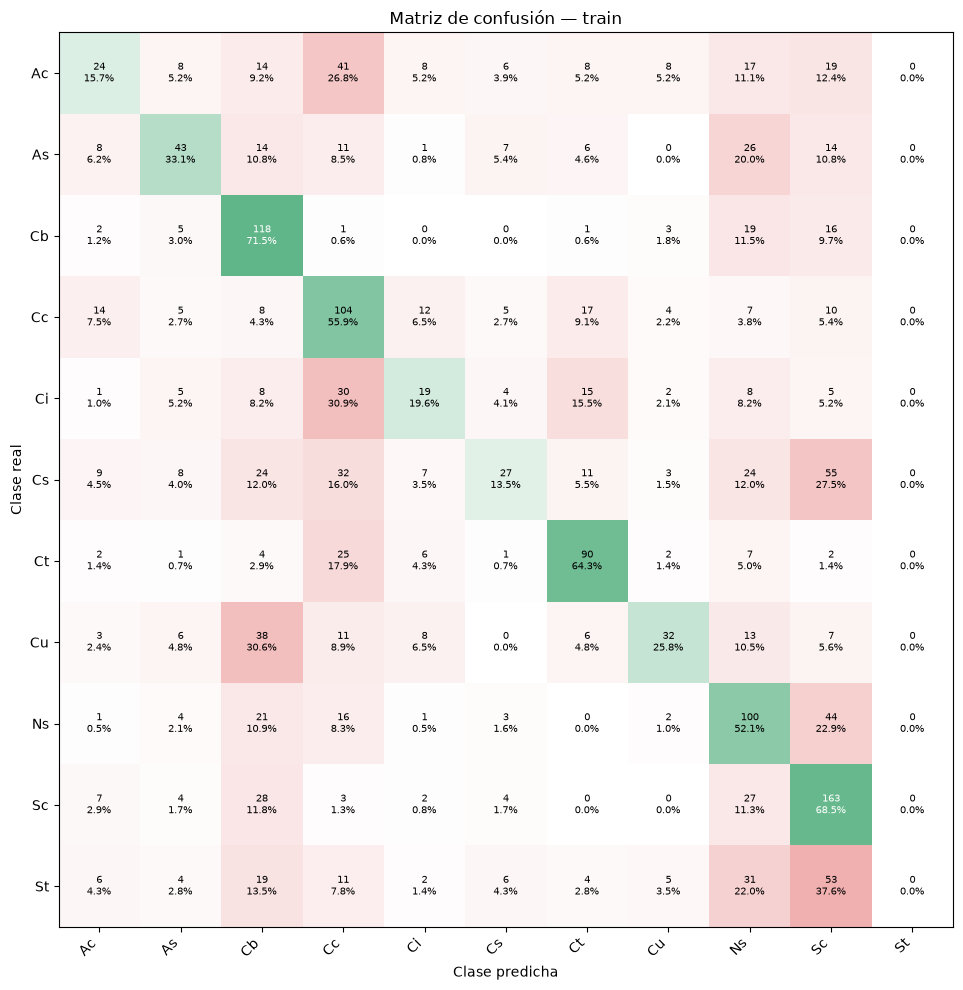

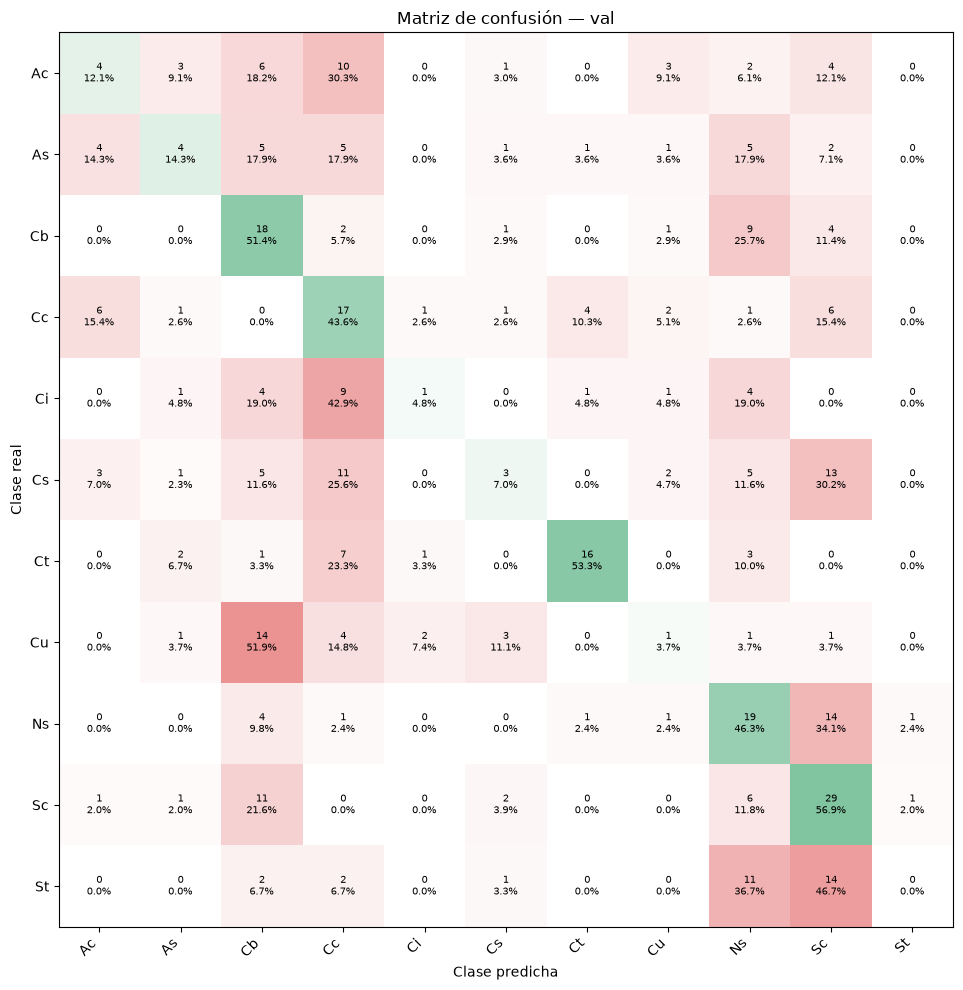

In [16]:
def dibujar_confusion(matriz, nombres, titulo, ruta):
    """Guarda matriz absoluta y porcentual con colores semánticos."""
    soporte = matriz.sum(axis=1, keepdims=True)
    fracciones = np.divide(
        matriz, soporte, out=np.zeros_like(matriz, dtype=float), where=soporte != 0
    )
    rgba = np.ones((*matriz.shape, 3))
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            base = np.array([0.13, 0.60, 0.35] if i == j else [0.85, 0.18, 0.18])
            rgba[i, j] = 1 - fracciones[i, j] * (1 - base)
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(rgba)
    ax.set_xticks(range(len(nombres)), nombres, rotation=45, ha="right")
    ax.set_yticks(range(len(nombres)), nombres)
    ax.set(xlabel="Clase predicha", ylabel="Clase real", title=titulo)
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            p = fracciones[i, j]
            ax.text(j, i, f"{matriz[i, j]}\n{p:.1%}", ha="center", va="center",
                    fontsize=7, color="white" if p > 0.65 else "black")
    fig.tight_layout()
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return fracciones

for split, resultado in resultados.items():
    cm = resultado["rep"].confusion_matrix.numpy()
    pd.DataFrame(cm, index=clases, columns=clases).to_csv(
        SALIDA / f"confusion_absoluta_{split}.csv"
    )
    fracciones = dibujar_confusion(
        cm, clases, f"Matriz de confusión — {split}",
        SALIDA / f"confusion_coloreada_{split}.png",
    )
    pd.DataFrame(fracciones, index=clases, columns=clases).to_csv(
        SALIDA / f"confusion_normalizada_{split}.csv"
    )